In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df=pd.read_csv('diabetes.csv')

In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### Exploratory Data Analysis (EDA)

First, let's check for any zero values in columns where they might indicate missing data, as a value of zero for these features is often biologically implausible.

In [ ]:
columns_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in columns_with_zeros:
    zero_count = (df[col] == 0).sum()
    if zero_count > 0:
        print(f"Column '{col}' has {zero_count} zero values.")


Column 'Glucose' has 5 zero values.
Column 'BloodPressure' has 35 zero values.
Column 'SkinThickness' has 227 zero values.
Column 'Insulin' has 374 zero values.
Column 'BMI' has 11 zero values.


Next, let's visualize the distribution of the target variable, 'Outcome', to see the balance of the classes.

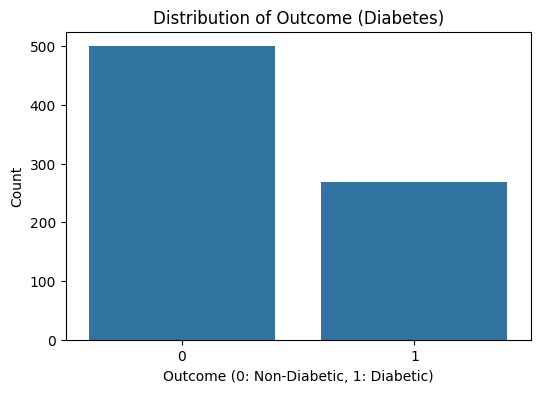

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df)
plt.title('Distribution of Outcome (Diabetes)')
plt.xlabel('Outcome (0: Non-Diabetic, 1: Diabetic)')
plt.ylabel('Count')
plt.show()


Now, let's look at the distributions of some key numerical features. We'll use histograms to understand their shapes and identify any outliers or unusual patterns.

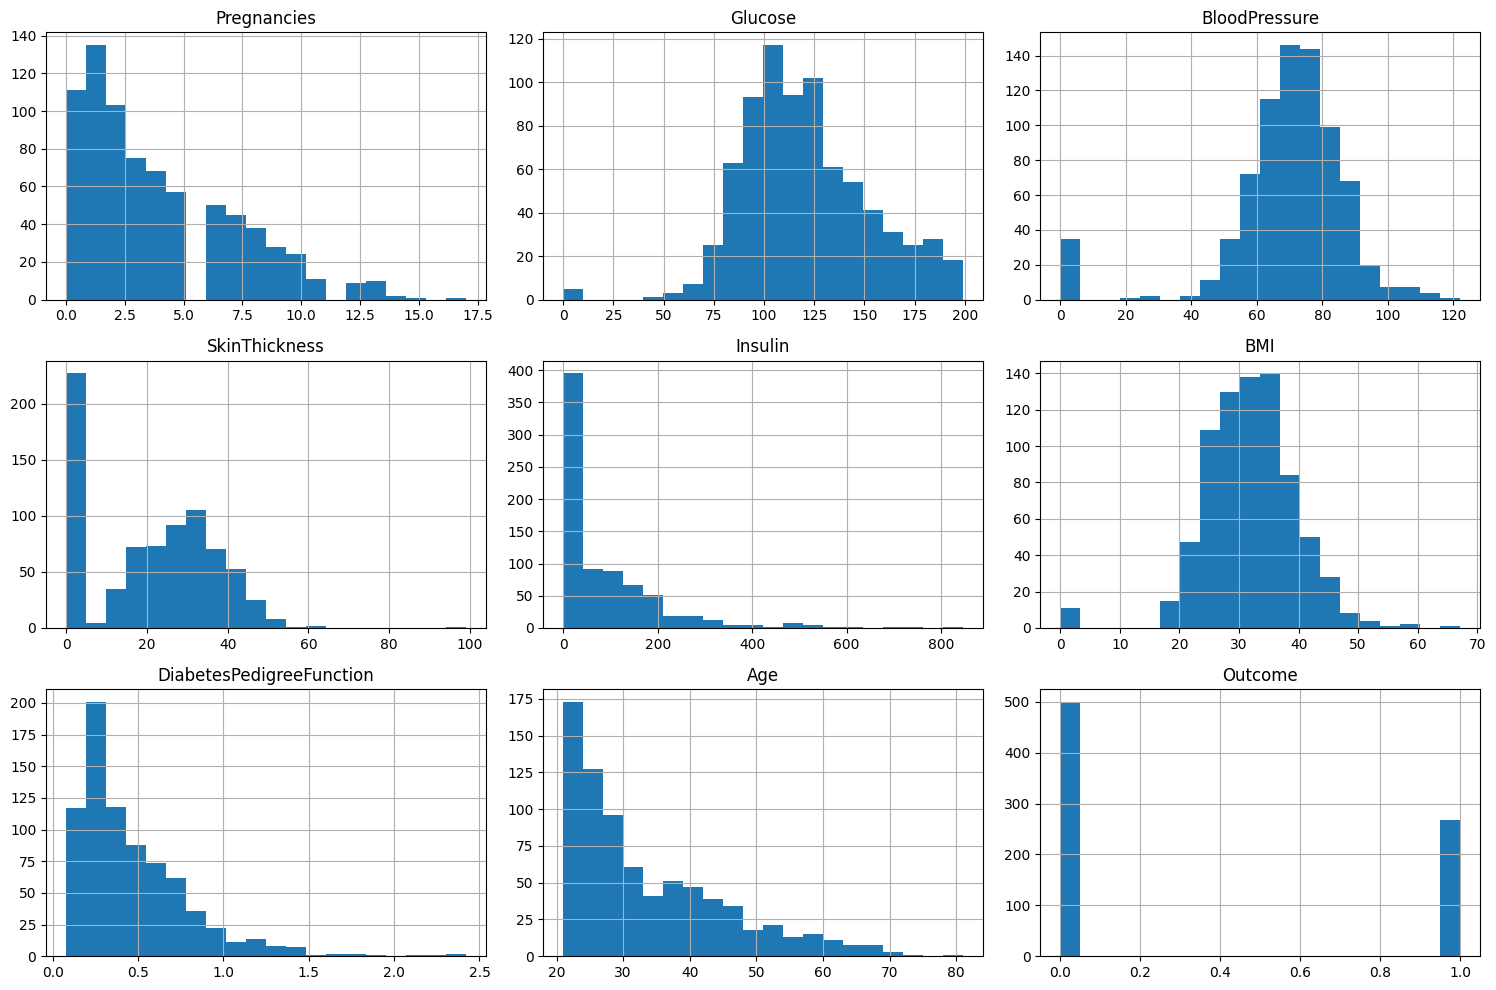

In [ ]:
df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()


Finally, let's examine the correlation matrix to understand the relationships between the different features.

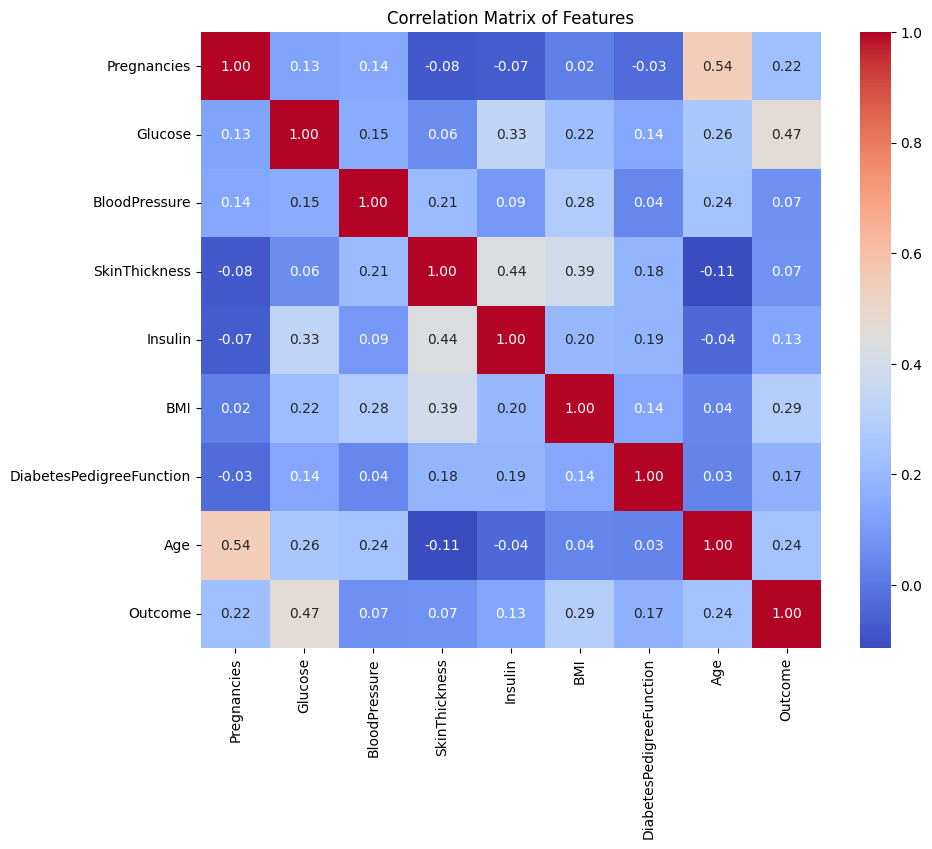

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Features')
plt.show()


### Data Cleaning: Handling Zero Values

As identified during EDA, several columns contain zero values that are biologically implausible and thus represent missing data. We will replace these zeros with the median of their respective columns, considering only non-zero values for the median calculation. This approach is often preferred over the mean for skewed distributions.

In [ ]:
df_cleaned = df.copy()

columns_to_impute = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in columns_to_impute:
    # Replace 0s with NaN for median calculation, then fill NaNs with the median of non-zero values
    df_cleaned[col] = df_cleaned[col].replace(0, np.nan)
    median_val = df_cleaned[col].median()
    df_cleaned[col] = df_cleaned[col].fillna(median_val)

print("Zero values after imputation:")
for col in columns_to_impute:
    zero_count = (df_cleaned[col] == 0).sum()
    print(f"Column '{col}' has {zero_count} zero values.")

Zero values after imputation:
Column 'Glucose' has 0 zero values.
Column 'BloodPressure' has 0 zero values.
Column 'SkinThickness' has 0 zero values.
Column 'Insulin' has 0 zero values.
Column 'BMI' has 0 zero values.


### Feature Importance Analysis

Now that we have cleaned the data, let's determine the importance of each feature in predicting the 'Outcome' (diabetes). We'll use a RandomForestClassifier model for this, as it inherently provides feature importance scores.

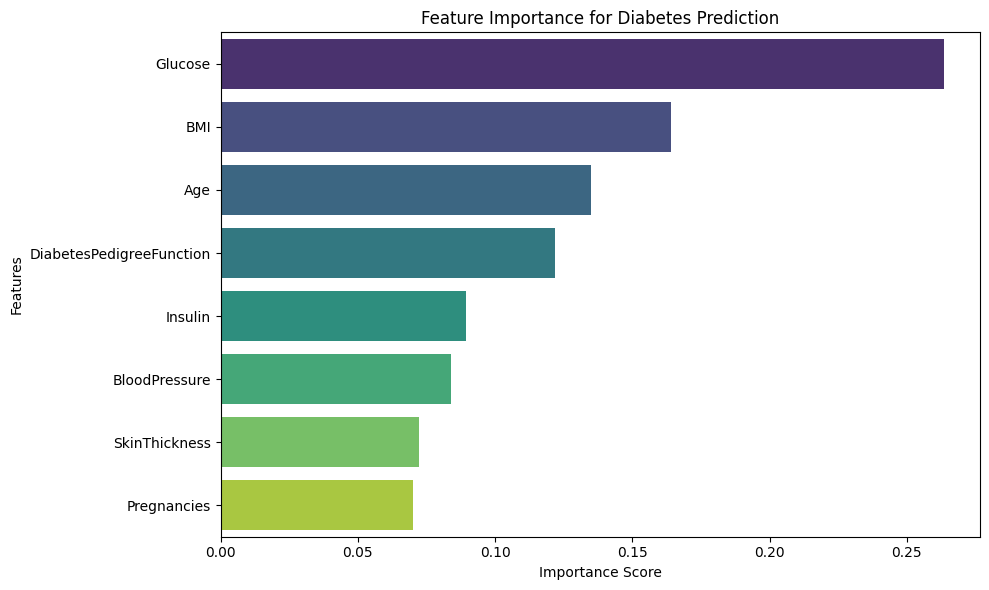

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Separate features (X) and target (y)
X = df_cleaned.drop('Outcome', axis=1)
y = df_cleaned['Outcome']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a RandomForestClassifier model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Get feature importances
feature_importances = pd.Series(model.feature_importances_, index=X.columns)

# Sort feature importances in descending order
feature_importances = feature_importances.sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis', hue=feature_importances.index, legend=False)
plt.title('Feature Importance for Diabetes Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Outlier Detection

Now, let's identify potential outliers in each of the numerical features using box plots. Outliers can significantly impact model performance, and understanding their presence is crucial for further data preprocessing.

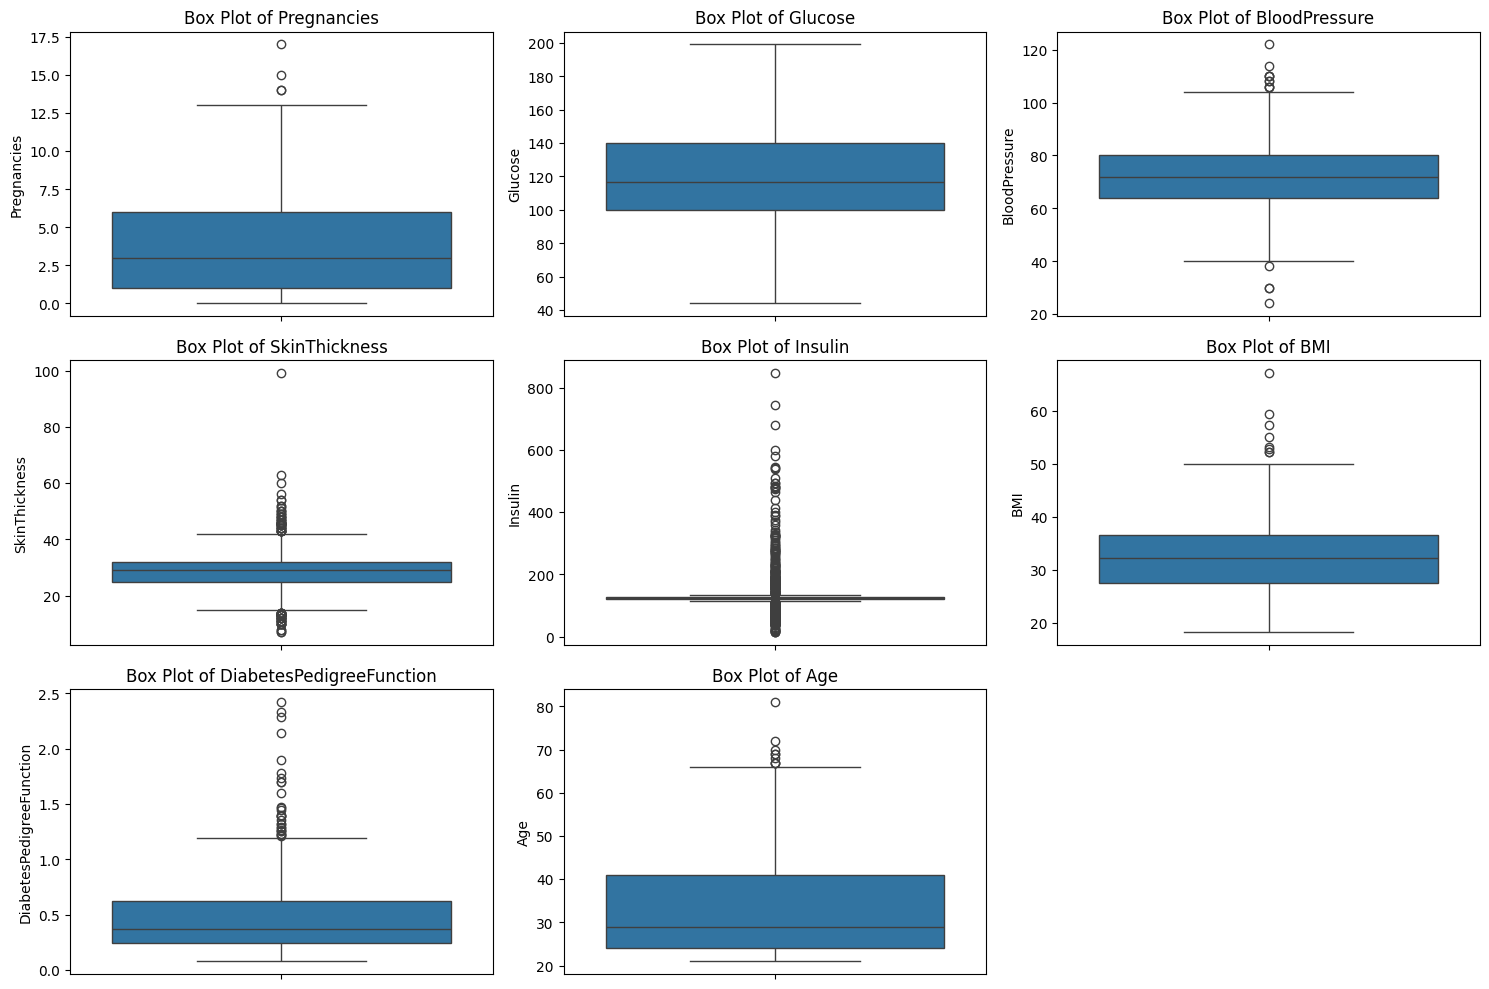

In [ ]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1) # Adjust subplot grid as needed
    sns.boxplot(y=df_cleaned[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

### Model Training and Evaluation: Logistic Regression

Now, let's train a Logistic Regression model and evaluate its performance on the test set (`X_test`, `y_test`). This will allow us to compare its effectiveness against the Random Forest Classifier.

Logistic Regression Accuracy: 0.7792
Logistic Regression Precision: 0.7333
Logistic Regression Recall: 0.6000
Logistic Regression F1-Score: 0.6600


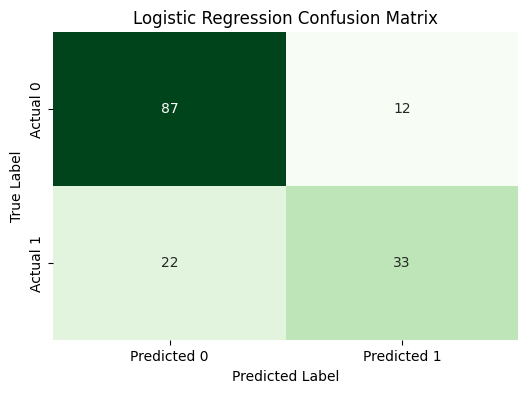

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Initialize and train a Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, solver='liblinear') # 'liblinear' solver is good for small datasets
log_reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test)

# Calculate evaluation metrics
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
precision_log_reg = precision_score(y_test, y_pred_log_reg)
recall_log_reg = recall_score(y_test, y_pred_log_reg)
f1_log_reg = f1_score(y_test, y_pred_log_reg)

print(f"Logistic Regression Accuracy: {accuracy_log_reg:.4f}")
print(f"Logistic Regression Precision: {precision_log_reg:.4f}")
print(f"Logistic Regression Recall: {recall_log_reg:.4f}")
print(f"Logistic Regression F1-Score: {f1_log_reg:.4f}")

# Display Confusion Matrix
cm_log_reg = confusion_matrix(y_test, y_pred_log_reg)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_log_reg, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
import pickle

# Save the Logistic Regression model
with open('diabetes_disease_modelLR.pkl', 'wb') as f:
    pickle.dump(log_reg_model, f)

print("Logistic Regression model saved as 'diabetes_disease_modelLR.pkl'")

Logistic Regression model saved as 'diabetes_disease_modelLR.pkl'
